# Emotion Classification in DreamBank Dream Reports

Code for the paper *Compatibility, Not Confirmation: What Emotion Patterns in 27,952 DreamBank Reports Can and Cannot Tell Us About Dream Theories.*

The notebook classifies the dominant Hall & Van de Castle (HVDC) emotion code in dream reports with TF-IDF features and a linear SVM. It reports a random-split evaluation, five-fold cross-validation, two baseline classifiers, emotion frequencies, the highest-weighted terms per class, and the main result used in the paper: **five-fold cross-validation grouped by dreamer**.

**Data:** not included. Download the DreamBank data (https://dreams.ucsc.edu), save it as `train.csv` next to this notebook, and check DreamBank's terms of use. Expected columns: `id, name, number, time, date, gender, age, report, character, emotion`.

**To run:** install the packages in `requirements.txt`, then run all cells from the top. All outputs below were saved from a full run.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

[nltk_data] Downloading package stopwords...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Load data

In [2]:
DATA_PATH = "train.csv"  # change this if your file is elsewhere
df = pd.read_csv(DATA_PATH)
print("Rows:", len(df))
df.head()

Rows: 27952


,id,name,number,time,date,gender,age,report,character,emotion
0,alta,Alta: a detailed dreamer,1,1985-1997,1957,F,A,"The one at the Meads's house, where it's bigge...","1MSA, 1FSA, 1FKA, 2ISA",NaN
1,alta,Alta: a detailed dreamer,2,1985-1997,8/11/1967,F,A,I'm at a family reunion in a large fine house ...,"2MSA, 2JSA",NaN
2,alta,Alta: a detailed dreamer,3,1985-1997,8/1/1985,F,A,I watch a plane fly past and shortly realize i...,"2ISA, 1FSA, 2ISA, 1MKA, 1MKA",NaN
3,alta,Alta: a detailed dreamer,4,1985-1997,1985?,F,A,Me pulling the green leaves and berries off so...,"1MSC, 1FKA, 2JSA, 1ANI, 2MSA, 1ANI",NaN
4,alta,Alta: a detailed dreamer,5,1985-1997,1985?,F,A,I'm in a room that reminds me of (but definite...,"1MKA, 2IOA, 1MKA, 2JSA, 1MSA","CO D, AN 1MKA"


## 3. Extract the dominant emotion label per dream

The `emotion` column stores HVDC codes (for example `AP D`, `AN 1MKA, CO D`). The code extracts the HVDC emotion categories mentioned (AP, AN, HA, CO, SD) and takes the **first-listed** one as the dominant label, giving a single-label classification problem.

Reports with no recognisable emotion code are labelled `NONE`. `NONE` may mean that no emotion was coded for the report, not that the dreamer felt no emotion, so it is treated as "no emotion coded".

**Limitation:** about 29% of emotion-coded reports contain more than one distinct category. Taking only the first-listed code discards the secondary emotions.

In [3]:
HVDC_CATEGORIES = ["AP", "AN", "HA", "CO", "SD"]

def extract_dominant_emotion(cell):
    if pd.isna(cell):
        return "NONE"
    codes = re.findall(r"\b(AP|AN|HA|CO|SD)\b", str(cell))
    if not codes:
        return "NONE"
    return codes[0]  # first-listed = dominant emotion

df["dominant_emotion"] = df["emotion"].apply(extract_dominant_emotion)
df["dominant_emotion"].value_counts()

dominant_emotion
NONE    16144
AP       4172
AN       2169
HA       2138
CO       2112
SD       1217
Name: count, dtype: int64

## 4. Clean the dream report text

Lowercase the text, remove leftover HTML line breaks, punctuation and numbers, and remove stopwords. Tokenisation is handled by TF-IDF.

In [4]:
stop_words = set(stopwords.words("english"))

# Keep a small set of negation words that a generic stopword list would remove,
# because they can change the meaning of an emotion word ("afraid" vs "not afraid").
KEEP_WORDS = {"not", "no", "never"}
stop_words = stop_words - KEEP_WORDS

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)      # strip leftover HTML line breaks
    text = re.sub(r"[^a-z\s]", " ", text)        # remove punctuation & numbers
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [w for w in text.split() if w not in stop_words]
    return " ".join(tokens)

df["clean_report"] = df["report"].apply(clean_text)
df[["report", "clean_report"]].head(3)

,report,clean_report
0,"The one at the Meads's house, where it's bigge...",one meads house bigger inside european village...
1,I'm at a family reunion in a large fine house ...,family reunion large fine house grounds maybe ...
2,I watch a plane fly past and shortly realize i...,watch plane fly past shortly realize low crash...


## 5. Build the modelling datasets

Two datasets are built:

- **5-class:** only reports with an HVDC emotion code (AP, AN, HA, CO, SD). This is the main dataset for the paper.
- **6-class (exploratory):** all reports, with `NONE` as a sixth class. Because `NONE` may mean "not coded", results for this version should be read with caution.

In [5]:
# drop empty reports
df = df[df["clean_report"].str.len() > 0].reset_index(drop=True)

# Option A: 5-class problem — only dreams with a coded Emotion
df_5class = df[df["dominant_emotion"] != "NONE"].reset_index(drop=True)

# Option B: 6-class problem — includes NONE
df_6class = df.copy()

print("5-class dataset size:", len(df_5class))
print(df_5class["dominant_emotion"].value_counts())
print()
print("6-class dataset size:", len(df_6class))
print(df_6class["dominant_emotion"].value_counts())

5-class dataset size: 11808
dominant_emotion
AP    4172
AN    2169
HA    2138
CO    2112
SD    1217
Name: count, dtype: int64

6-class dataset size: 27951
dominant_emotion
NONE    16143
AP       4172
AN       2169
HA       2138
CO       2112
SD       1217
Name: count, dtype: int64


## 6. TF-IDF + SVM training function

A reusable function that splits the data (stratified 80/20), builds TF-IDF features (unigrams and bigrams, 5,000 terms), trains a linear SVM with balanced class weights, and reports accuracy, macro precision, macro recall and macro F1.

In [6]:
def run_svm_pipeline(data, label_col="dominant_emotion", text_col="clean_report", test_size=0.2):
    X = data[text_col]
    y = data[label_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )

    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    clf = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000)
    clf.fit(X_train_tfidf, y_train)

    y_pred = clf.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0
    )

    print("Accuracy:", round(acc, 4))
    print("Macro Precision:", round(precision, 4))
    print("Macro Recall:", round(recall, 4))
    print("Macro F1:", round(f1, 4))
    print()
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title("Confusion Matrix")
    plt.show()

    return clf, vectorizer, {
        "accuracy": acc, "precision": precision, "recall": recall, "f1": f1
    }

## 7. Run: 5-class model

=== 5-CLASS MODEL (emotion-coded dreams only) ===
Accuracy: 0.6791
Macro Precision: 0.6547
Macro Recall: 0.6579
Macro F1: 0.6561

              precision    recall  f1-score   support

          AN       0.70      0.74      0.72       434
          AP       0.74      0.72      0.73       835
          CO       0.65      0.63      0.64       422
          HA       0.67      0.67      0.67       428
          SD       0.52      0.53      0.53       243

    accuracy                           0.68      2362
   macro avg       0.65      0.66      0.66      2362
weighted avg       0.68      0.68      0.68      2362



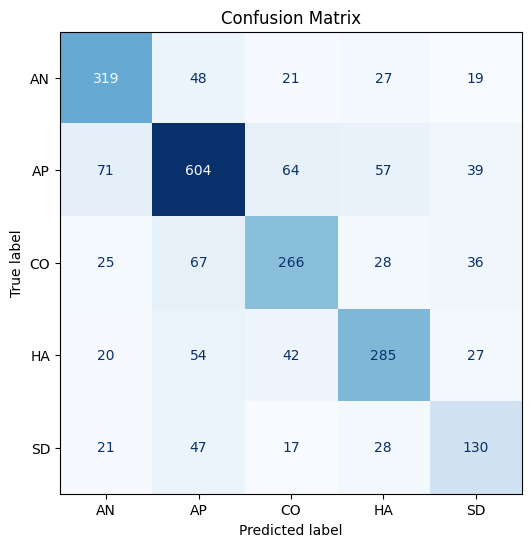

In [7]:
print("=== 5-CLASS MODEL (emotion-coded dreams only) ===")
clf_5, vec_5, metrics_5 = run_svm_pipeline(df_5class)

## 8. Run: 6-class model (exploratory, includes NONE)

=== 6-CLASS MODEL (includes NONE) ===
Accuracy: 0.7542
Macro Precision: 0.6207
Macro Recall: 0.6177
Macro F1: 0.6187

              precision    recall  f1-score   support

          AN       0.63      0.68      0.65       434
          AP       0.66      0.61      0.63       835
          CO       0.59      0.54      0.56       422
          HA       0.56      0.57      0.56       428
        NONE       0.87      0.88      0.87      3229
          SD       0.43      0.44      0.43       243

    accuracy                           0.75      5591
   macro avg       0.62      0.62      0.62      5591
weighted avg       0.75      0.75      0.75      5591



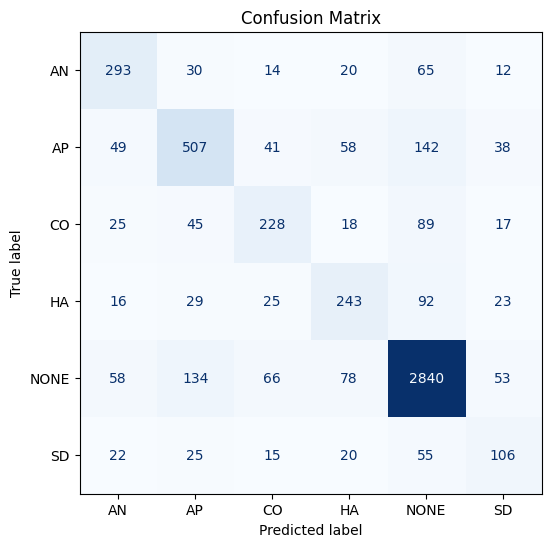

In [8]:
print("=== 6-CLASS MODEL (includes NONE) ===")
clf_6, vec_6, metrics_6 = run_svm_pipeline(df_6class)

## 9. Five-fold cross-validation (random stratified split)

A robustness check on the single train/test split. Note that this version does **not** keep each dreamer's reports together, so the grouped version in section 14 is the main result.

In [9]:
def run_kfold(data, k=5, label_col="dominant_emotion", text_col="clean_report"):
    X_text = data[text_col]
    y = data[label_col]
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X = vectorizer.fit_transform(X_text)
    clf = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(clf, X, y, cv=skf, scoring="f1_macro")
    print(f"{k}-fold macro F1 scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))
    return scores

print("5-class k-fold:")
scores_5 = run_kfold(df_5class)
print()
print("6-class k-fold:")
scores_6 = run_kfold(df_6class)

5-class k-fold:
5-fold macro F1 scores: [0.6598 0.6502 0.6493 0.652  0.6453]
Mean: 0.6513 | Std: 0.0048

6-class k-fold:
5-fold macro F1 scores: [0.6282 0.6149 0.6212 0.6228 0.6213]
Mean: 0.6217 | Std: 0.0043


## 10. Emotion frequency distribution

Frequencies of the dominant emotion across all reports, and among emotion-coded reports only.

dominant_emotion
No emotion coded    57.75
Apprehension        14.93
Anger                7.76
Happiness            7.65
Confusion            7.56
Sadness              4.35
Name: proportion, dtype: float64


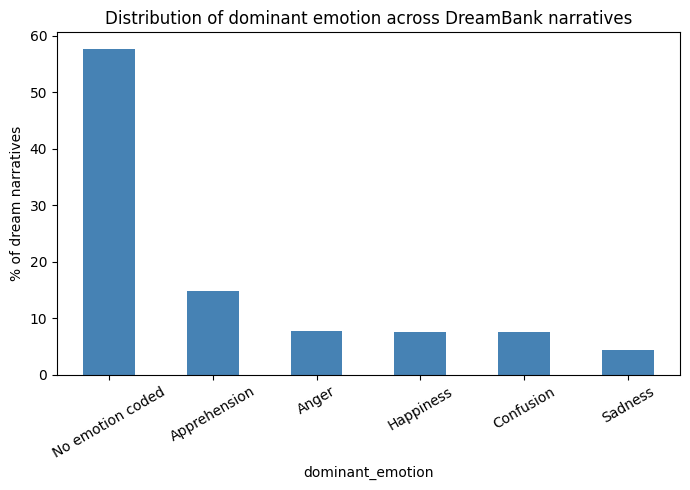


Among emotion-coded dreams only:
dominant_emotion
Apprehension    35.33
Anger           18.37
Happiness       18.11
Confusion       17.89
Sadness         10.31
Name: proportion, dtype: float64


In [10]:
label_names = {
    "AP": "Apprehension", "AN": "Anger", "HA": "Happiness",
    "CO": "Confusion", "SD": "Sadness", "NONE": "No emotion coded"
}

dist = df["dominant_emotion"].value_counts(normalize=True).rename(index=label_names) * 100
print(dist.round(2))

fig, ax = plt.subplots(figsize=(7, 5))
dist.sort_values(ascending=False).plot(kind="bar", ax=ax, color="steelblue")
ax.set_ylabel("% of dream narratives")
ax.set_title("Distribution of dominant emotion across DreamBank narratives")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("emotion_distribution.png", dpi=200)
plt.show()

# Among ONLY emotion-coded reports (excludes NONE): relative proportions of the five categories
dist_coded = df_5class["dominant_emotion"].value_counts(normalize=True).rename(index=label_names) * 100
print("\nAmong emotion-coded dreams only:")
print(dist_coded.round(2))

## 11. Feature importance

The highest-weighted TF-IDF terms for each class in the 5-class SVM. Because the HVDC coding rules place guilt and embarrassment within the Apprehension class, terms such as *embarrassed* and *guilty* appearing under AP reflect how the coding scheme is defined.

In [11]:
def top_terms_per_class(clf, vectorizer, top_n=15):
    feature_names = np.array(vectorizer.get_feature_names_out())
    for i, class_label in enumerate(clf.classes_):
        coefs = clf.coef_[i]
        top_idx = np.argsort(coefs)[-top_n:][::-1]
        print(f"\nTop terms for class '{class_label}':")
        print(", ".join(feature_names[top_idx]))

top_terms_per_class(clf_5, vec_5)


Top terms for class 'AN':
angry, annoyed, mad, frustrated, anger, angrily, disgusted, furious, annoying, disgust, jealous, irritated, pissed, aggravated, rage

Top terms for class 'AP':
worried, embarrassed, afraid, scared, nervous, concerned, uncomfortable, anxious, frightened, guilty, ashamed, fear, uneasy, scary, panicked

Top terms for class 'CO':
surprised, confused, amazed, shocked, surprise, wondered, startled, puzzled, wondering, perplexed, shock, questions perplexed, appalled, confusing, strange

Top terms for class 'HA':
happy, glad, pleased, enjoying, relieved, excited, thoughts happy, wonderful, delighted, pleasant, felt good, thrilled, happily, joy, fun

Top terms for class 'SD':
sad, disappointed, sorry, unhappy, crying, felt bad, lonely, depressed, sobbing, sadness, cry, regret, cried, distressed, distraught


## 12. Export tables

Saves the results tables and the emotion-distribution figure so the numbers in the paper can be traced back to this notebook.

In [12]:
results_summary = pd.DataFrame([
    {"model": "5-class SVM", **metrics_5},
    {"model": "6-class SVM", **metrics_6},
])
results_summary.to_csv("results_summary.csv", index=False)
dist.to_csv("emotion_distribution_all.csv")
dist_coded.to_csv("emotion_distribution_coded_only.csv")

print(results_summary)
print("\nSaved: results_summary.csv, emotion_distribution_all.csv, emotion_distribution_coded_only.csv, emotion_distribution.png")

         model  accuracy  precision    recall        f1
0  5-class SVM  0.679086   0.654689  0.657915  0.656146
1  6-class SVM  0.754248   0.620703  0.617681  0.618719

Saved: results_summary.csv, emotion_distribution_all.csv, emotion_distribution_coded_only.csv, emotion_distribution.png


## 13. Baseline comparison (most-frequent and stratified-random)

Two baseline classifiers give a reference point, because accuracy alone can look high when one class dominates.

In [13]:
from sklearn.dummy import DummyClassifier

def baseline_comparison(data, label_col='dominant_emotion', text_col='clean_report', test_size=0.2, tag=''):
    X = data[text_col]
    y = data[label_col]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    rows = []
    for strategy in ['most_frequent', 'stratified']:
        dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
        dummy.fit(X_train_tfidf, y_train)
        y_pred = dummy.predict(X_test_tfidf)
        acc = accuracy_score(y_test, y_pred)
        _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
        rows.append({'model': f'{tag} baseline ({strategy})', 'accuracy': acc, 'f1_macro': f1})
    return pd.DataFrame(rows)

baseline_5 = baseline_comparison(df_5class, tag='5-class')
baseline_6 = baseline_comparison(df_6class, tag='6-class')

comparison = pd.concat([
    baseline_5,
    pd.DataFrame([{'model': '5-class SVM', 'accuracy': metrics_5['accuracy'], 'f1_macro': metrics_5['f1']}]),
    baseline_6,
    pd.DataFrame([{'model': '6-class SVM', 'accuracy': metrics_6['accuracy'], 'f1_macro': metrics_6['f1']}]),
], ignore_index=True)

print(comparison)
comparison.to_csv('baseline_comparison.csv', index=False)


                              model  accuracy  f1_macro
0  5-class baseline (most_frequent)  0.353514  0.104473
1     5-class baseline (stratified)  0.236664  0.196735
2                       5-class SVM  0.679086  0.656146
3  6-class baseline (most_frequent)  0.577535  0.122033
4     6-class baseline (stratified)  0.383116  0.172325
5                       6-class SVM  0.754248  0.618719


## 14. Dreamer-grouped cross-validation (main result in the paper)

Five-fold stratified cross-validation in which all reports from the same dreamer or series (the `id` column) stay in the same fold, so no dreamer appears in both training and test data. The TF-IDF step is inside the pipeline, so it is fitted on the training folds only. The two baselines use the same folds.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier

def grouped_cv(data, k=5, label_col="dominant_emotion", text_col="clean_report", group_col="id"):
    X, y, groups = data[text_col], data[label_col], data[group_col]
    print("Unique dreamers/series:", groups.nunique())

    cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    svm = make_pipeline(
        TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
        LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000),
    )
    scores = cross_val_score(svm, X, y, groups=groups, cv=cv, scoring="f1_macro")
    print("SVM grouped macro F1:", np.round(scores, 4),
          "| Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))

    for strategy in ["most_frequent", "stratified"]:
        dummy = make_pipeline(
            TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
            DummyClassifier(strategy=strategy, random_state=RANDOM_STATE),
        )
        s = cross_val_score(dummy, X, y, groups=groups, cv=cv, scoring="f1_macro")
        print(f"Baseline ({strategy}) macro F1 mean:", round(s.mean(), 4))
    return scores

print("=== 5-CLASS, GROUPED BY DREAMER ===")
grouped_5 = grouped_cv(df_5class)

=== 5-CLASS, GROUPED BY DREAMER ===
Unique dreamers/series: 72
SVM grouped macro F1: [0.6729 0.6191 0.6305 0.6415 0.6359] | Mean: 0.64 | Std: 0.018
Baseline (most_frequent) macro F1 mean: 0.1034
Baseline (stratified) macro F1 mean: 0.1959


## 15. Size of the largest dreamer series

The 5-class data come from 72 dreamers or series. The largest series (`b`, 2,010 reports) accounts for about 17% of the coded reports.

In [15]:
print(df_5class["id"].value_counts().head(10))

id
b              2010
izzy-all       1018
b2              795
elizabeth       778
hall_female     594
kenneth         560
emma            442
alta            273
norms-f         273
norman          251
Name: count, dtype: int64


## Notes

- Only the first-listed emotion code is used per report. About 29% of coded reports contain more than one category, so multi-label modelling is a natural extension.
- A few dreamers contribute a large share of the data, so the overall emotion pattern may partly reflect those dreamers.
- The classifier learns the HVDC coding categories, which human coders assigned partly from the emotion words in each report. Good performance shows the labels are consistent, not that any theory of dreaming is correct.
- Random seed: 42. Exact scores can differ slightly across scikit-learn versions because of how folds are assigned.